# 1. Introduction

Author : Bara Samudra Syuhada

Pada project kali ini akan dilakukan klasifikasi data gambar terumbu karang menggunakan deep learning.

URL Dataset: \
https://www.kaggle.com/datasets/aneeshdighe/corals-classification/data

Problem: \
Terumbu karang berperan penting dalam menjaga keseimbangan ekosistem laut seperti perlindungan pantai, penyedia habitat dan penyedia makanan bagi spesies laut (Yuan et al., 2024). Namun, fenomena seperti perubahan iklim dan peningkatan suhu laut membuat ekosistem ini rentan terhadap pemutihan (bleaching)(Hughes et al., 2003, 2017) dimana karang mengalami tekanan dan melepaskan simbiosisnya dengan alga (https://coral.org/blog/what-is-coral-bleaching-and-why-should-you-care/). Hal ini menyebabkan ekosistem laut terganggu. Dengan mengidentifikasi coral bleaching, stakeholder dapat segera menangani pemutihan karang sejak dini dengan melakukan perencanaan untuk restorasi. Klasifikasi bleaching dengan bantuan deep learning ini diharapkan mampu mempermudah perencanaan restorasi tersebut.

Justifikasi:
- Hughes, T. P., Baird, A., & Connolly, S. R. (2003). Climate change, human impacts, and the resilience of coral reefs. Science, 301, 929–933.https://doi.org/10.1126/science.108504
- Hughes, T. P., Kerry, J. T., Álvarez-Noriega, M., Álvarez-Romero, J. G., Anderson, K. D., Baird, A. H., Babcock, R. C., Beger, M., Bellwood, D. R., Berkelmans, R., Bridge, T. C., Butler, I. R., Byrne, M., Cantin, N. E., Comeau, S., Connolly, S. R., Cumming, G. S., Dalton, S. J., Diaz-Pulido, G., … Wilson, S. K. (2017). Global warming and recurrent mass bleaching of corals. Nature, 543(7645), 373–377. https://doi.org/10.1038/nature21707
- Yuan, M. H., Lin, K. T., Pan, S. Y., & Yang, C. K. (2024). Exploring coral reef benefits: A systematic SEEA-driven review. In Science of the Total Environment (Vol. 950). Elsevier B.V.
https://doi.org/10.1016/j.scitotenv.2024.175237
- https://coral.org/blog/what-is-coral-bleaching-and-why-should-you-care/

User:
- Pemerintah daerah, aktivis lingkungan, NGO, masyarkat lokal yang turut serta terlibat dalam proyek restorasi ekosistem terumbu karang

# 2. Import Libraries

Bagian ini hanya akan mengimport library yang digunakan pada project

In [1]:
# Import libraries

import os
import cv2
import glob
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

from keras.applications.resnet50 import ResNet50, preprocess_input as preprocess_input_resnet50

from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Check TensorFlow version
print(tf.__version__)

2.20.0


In [2]:
# Install Kaggle library in Google Collab

## Install Kaggle library
!pip install -q kaggle

## Make a directory named `.kaggle`
!mkdir ~/.kaggle

## Copy the kaggle.json into this new directory
!cp kaggle.json ~/.kaggle/

## Change permission for this directory :
!chmod 600 ~/.kaggle/kaggle.json

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


# 3. Data Loading

Bagian ini merupakan proses pengambilan data yang bersumber dari Kaggle dan pengecekan ukuran dataset

Source dataset : [URL](https://www.kaggle.com/datasets/aneeshdighe/corals-classification)

In [3]:
%%time
# Download Dataset
# Source dataset : https://www.kaggle.com/datasets/aneeshdighe/corals-classification

!kaggle datasets download -d aneeshdighe/corals-classification

Dataset URL: https://www.kaggle.com/datasets/aneeshdighe/corals-classification
License(s): DbCL-1.0
Resuming from 81788928 bytes (58710212 bytes left)...
100% 134M/134M [00:00<00:00, 78.6MB/s]

CPU times: user 9.2 ms, sys: 3.35 ms, total: 12.6 ms
Wall time: 1.92 s


In [4]:
# Every dataset that downloaded from Kaggle is in format `.zip`. So, we must unzip it before we can using the dataset.

!unzip -qq ./corals-classification.zip

In [5]:
# Define path

main_path = '/content/Bleached Corals and Healthy Corals Classification'
train_path = os.path.join(main_path, 'Training')
test_path = os.path.join(main_path, 'Testing')
val_path = os.path.join(main_path, 'Validation')

In [6]:
# Check how many data in `train_path` and `test_path`

def check_path(path):
  labels = os.listdir(path)
  for label in labels:
    num_data = len(os.listdir(os.path.join(path, label)))
    print(f'Total Data - {label} : {num_data}')

print('Train Path')
check_path(train_path)
print('')

print('Test Path')
check_path(test_path)
print('')

print('Validation Path')
check_path(val_path)
print('')

Train Path
Total Data - bleached_corals : 3880
Total Data - healthy_corals : 3504

Test Path
Total Data - bleached_corals : 485
Total Data - healthy_corals : 438

Validation Path
Total Data - bleached_corals : 485
Total Data - healthy_corals : 500



# 4. Exploratory Data Analysis (EDA)

Bagian ini akan mengeksplor data dengan menampilkan beberapa gambar dari tiap data (train, test, dan validation) serta melihat dimensi gambar dan nilai piksel gambar indeks ke [0,0] dari contoh gambar yang ditampilkan

In [7]:
# Function to visualize the first 5 images from each class and its corresponding shape & sample value (index[0,0])

def images_info(path):
  labels = os.listdir(path)
  for label in labels:
    folder_path = os.path.join(path, label)
    fig = plt.figure(figsize=(20, 20))
    columns = 5
    rows = 1
    print('Class : ', label)
    images = os.listdir(folder_path)
    for index in range(1, columns*rows +1):
        fig.add_subplot(rows, columns, index)
        image = plt.imread(os.path.join(folder_path, images[index]))
        plt.imshow(image)
        plt.axis("off")
        print(f"dimensi gambar ke- {index}: {image.shape}")
        print(f"pixel value (r, g, b) index [0,0] gambar ke - {index}: {image[0,0]}")
        print()
    plt.show()

Class :  bleached_corals
dimensi gambar ke- 1: (221, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [101 105 108]

dimensi gambar ke- 2: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [ 27 146 166]

dimensi gambar ke- 3: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [75 86 28]

dimensi gambar ke- 4: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [125  87   2]

dimensi gambar ke- 5: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [193 140  10]



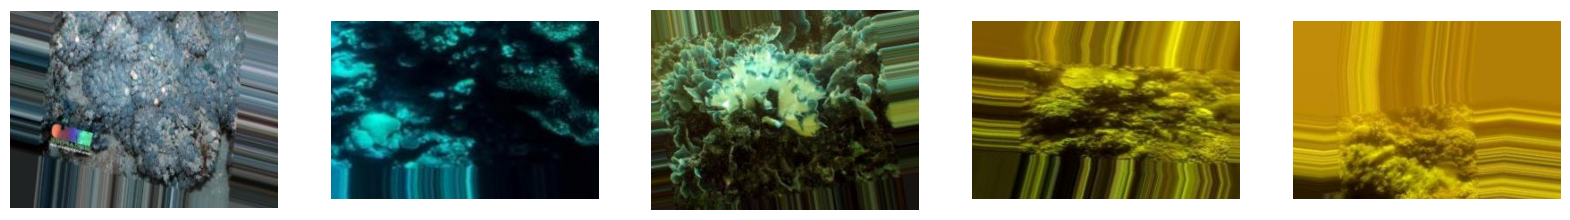

Class :  healthy_corals
dimensi gambar ke- 1: (300, 225, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [ 69 121 109]

dimensi gambar ke- 2: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [53 41 43]

dimensi gambar ke- 3: (210, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [76 65 35]

dimensi gambar ke- 4: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [242 210  99]

dimensi gambar ke- 5: (199, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [142 114   4]



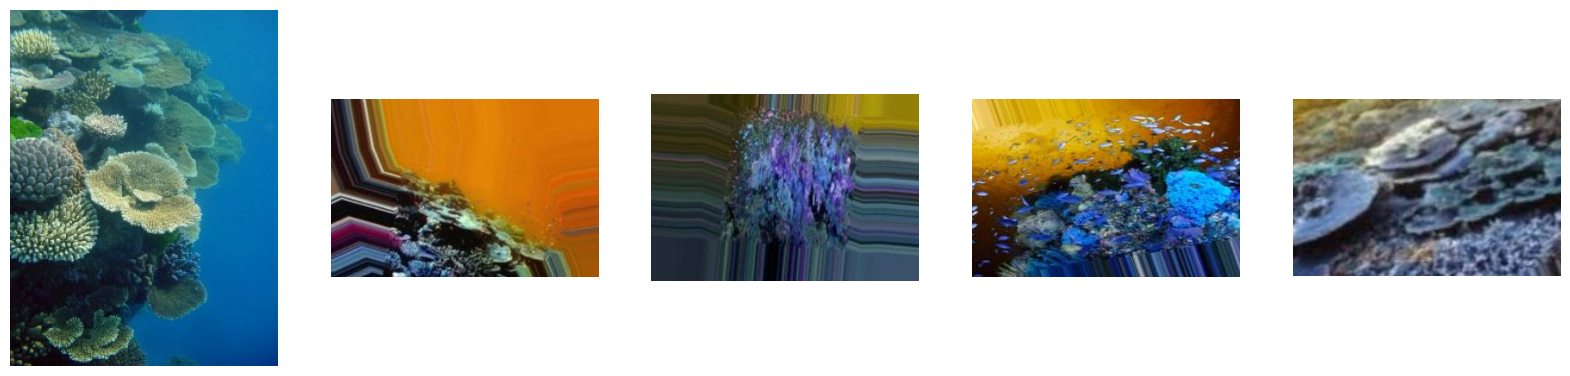

In [8]:
# Visualization of train_path

images_info(train_path)

Class :  bleached_corals
dimensi gambar ke- 1: (217, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [28 23 20]

dimensi gambar ke- 2: (217, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [96 92 93]

dimensi gambar ke- 3: (221, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [184 174 173]

dimensi gambar ke- 4: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [12 75 67]

dimensi gambar ke- 5: (221, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [43 54 50]



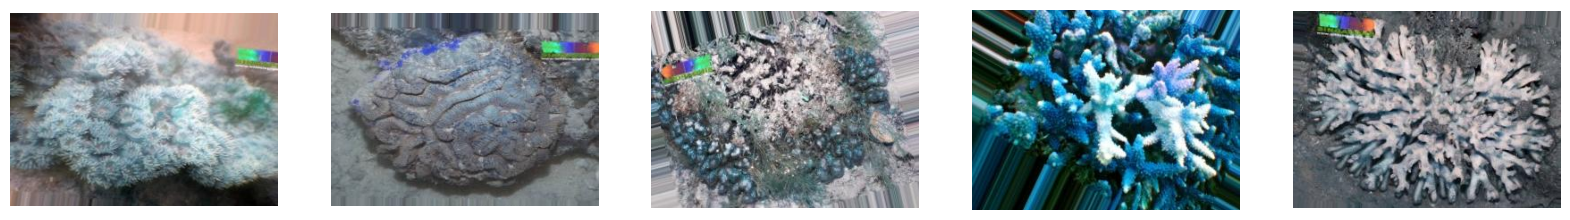

Class :  healthy_corals
dimensi gambar ke- 1: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [250 106  80]

dimensi gambar ke- 2: (250, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [182 204 202]

dimensi gambar ke- 3: (300, 161, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [111  24   0]

dimensi gambar ke- 4: (300, 200, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [255 228  14]

dimensi gambar ke- 5: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [210 169   1]



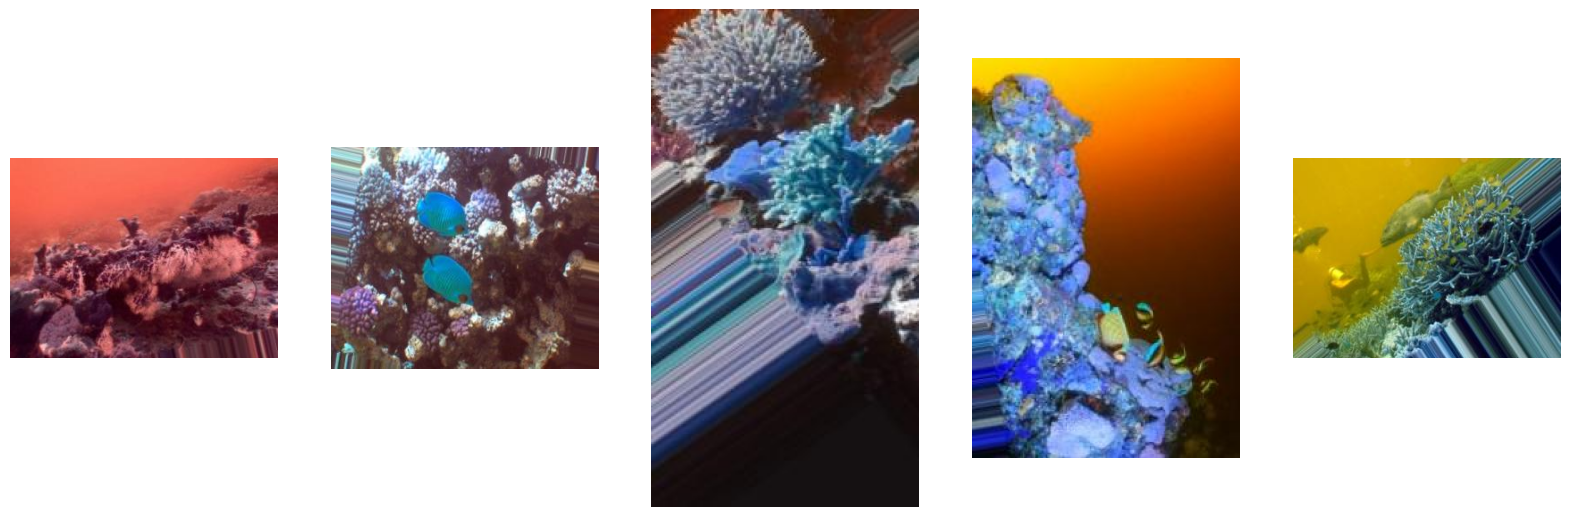

In [9]:
# Visualization of `test_path`

images_info(test_path)

Class :  bleached_corals
dimensi gambar ke- 1: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [146 135 152]

dimensi gambar ke- 2: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [  3 178 233]

dimensi gambar ke- 3: (221, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [45 99 65]

dimensi gambar ke- 4: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [23 65 51]

dimensi gambar ke- 5: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [ 4 56 96]



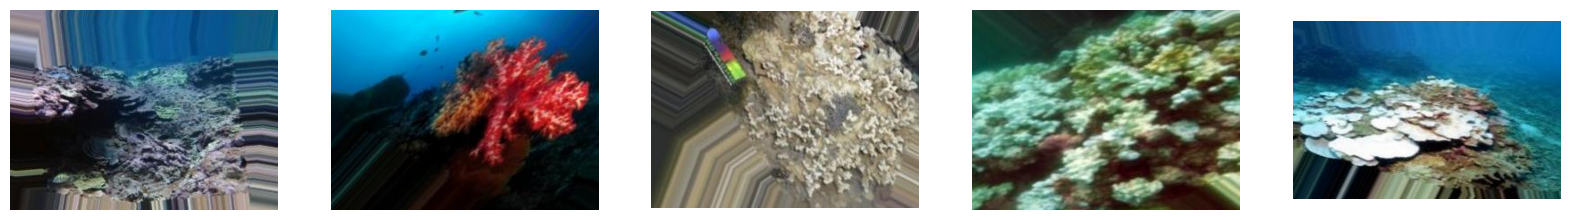

Class :  healthy_corals
dimensi gambar ke- 1: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 1: [227 215 193]

dimensi gambar ke- 2: (200, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 2: [48 25  7]

dimensi gambar ke- 3: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 3: [  0 100 186]

dimensi gambar ke- 4: (225, 300, 3)
pixel value (r, g, b) index [0,0] gambar ke - 4: [  4 114 127]

dimensi gambar ke- 5: (300, 247, 3)
pixel value (r, g, b) index [0,0] gambar ke - 5: [  3 130 225]



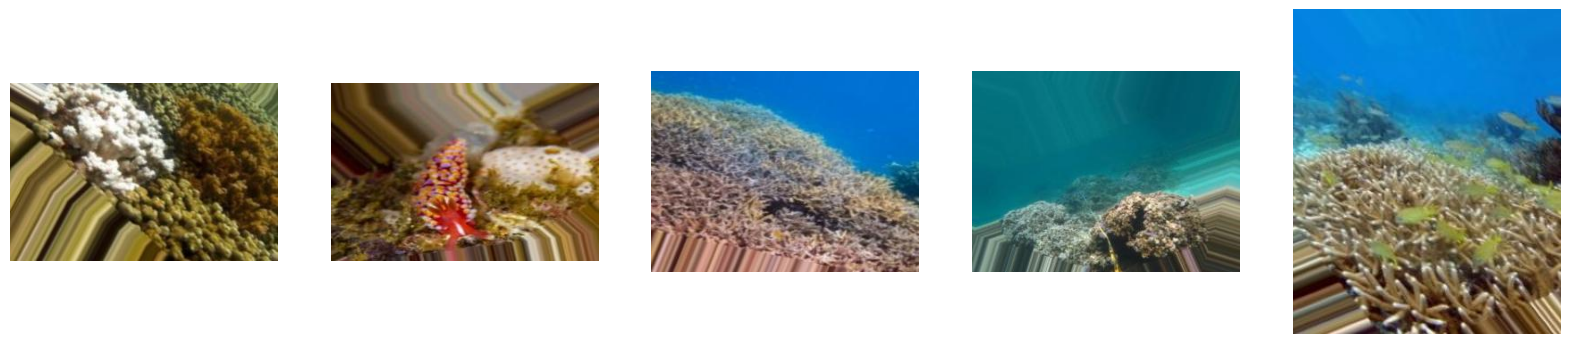

In [10]:
# Visualization of `val_path`

images_info(val_path)

Terlihat data dari [sumber](https://www.kaggle.com/datasets/aneeshdighe/corals-classification) memiliki dimensi (height x width) yang bervariasi. Selain itu, dapat dilihat juga sampel nilai RGB dari piksel pertama (index[0,0]) tiap contoh gambar. Nilai tersebut memiliki rentang 0-255.

### Karakteristik data

Dari data yang diperoleh, gambar diklasifikan menjadi menjadi `healthy corals` dan `bleached corals` dimana berdasarkan karakteristik kedua kelas tersebut berbeda. `Healthy corals` merupakan karang yang masih sehat, terlihat dari warnanya yang beraneka ragam dan menjadi habitat dari fauna laut (dikelilingi ikan). Sementara itu, `bleached corals` merupakan karang yang rusak akibat pemutihan sehingga ekosistem karang didominasi warna putih dan karang terlihat 'kering' (tidak hidup / dikelilingi fauna).

# 5. Feature Engineering

Berdasarkan keterangan dari [sumber](https://www.kaggle.com/datasets/aneeshdighe/corals-classification), dataset yang ada telah dilakukan augmentasi sehingga pada bagian ini tidak akan dilakukan augmentasi lagi pada data. Hal ini juga terlihat pada bagian Exploratory Data Analysis (EDA) dimana data ada yang terdistorsi. Ini merupakan salah satu bukti bahwa data telah dilakukan augmentasi.

 Selain itu, pada EDA terlihat bahwa dimensi gambar belum seragam dengan `height` & `width` sekitar 160 hingga 300. Nilai piksel pada gambar juga masih memiliki rentang dari 0-255. Oleh karena itu pada bagian ini gambar akan di resize menjadi ukuran 200 x 225 dan dilakukan rescale agar rentang pixel value menjadi 0-1 saja. Ukuran 200 x 225 dipilih karena dianggap ideal untuk `height` dan `width` pada dataset ini setelah dilakukan percobaan / trial and error. Selain itu, untuk proses rescale, nilai piksel dari tiap gambar akan dikalikan dengan 1/255 agar rentang nilai piksel menjadi 0-1 saja.

In [11]:
# Define hyperparameters

img_height= 200
img_width= 225
batch_size= 64

In [12]:
# Create batch generator for train-set, val-set, and test-set

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)

train_set = train_datagen.flow_from_directory(train_path,
                                              target_size=(img_height,img_width),
                                              class_mode='sparse',
                                              batch_size=batch_size,
                                              shuffle=False,
                                              seed=2)

val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)

val_set = val_datagen.flow_from_directory(val_path,
                                            target_size=(img_height,img_width),
                                            class_mode='sparse',
                                            batch_size=batch_size,
                                            shuffle=False,
                                            seed=2)

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)

test_set = test_datagen.flow_from_directory(test_path,
                                            target_size=(img_height,img_width),
                                            class_mode='sparse',
                                            batch_size=batch_size,
                                            shuffle=False,
                                            seed=2)

Found 7384 images belonging to 2 classes.
Found 985 images belonging to 2 classes.
Found 923 images belonging to 2 classes.


In [13]:
# Show labels

train_set.class_indices

{'bleached_corals': 0, 'healthy_corals': 1}

Setelah dilakukan proses feature engineering kelas dataset menjadi 0 (untuk `bleached_corals`) dan 1 (untuk `healthy_corals`). Data train terdiri dari 7384 data, validation terdiri dari 985 data, dan 923 data yang terbagi dalam dua kelas tersebut.

# 6. ANN Model

Pertama-tama model akan dibuat menggunakan Convolutional Neural Network (CNN). Convolutional neural network menggunakan data tiga dimensi untuk klasifikasi gambar dan tugas pengenalan objek (https://www.ibm.com/id-id/think/topics/convolutional-neural-networks).

## 6.1. Model Definition

Model didefinisikan secara sequential dan memiliki arsitektur yang berisi dengan 5 convolutional layers dengan rinician sebagai berikut:
- Layer pertama merupakan convolutional layer dengan filters (dimensi ruang output) = 32 dan kernel size 3 x 3. Selain itu fungsi aktivasi menggunakan relu dan input shape sesuai dengan dimensi data yang telah didefinisikan (200 x 225 x 3). Selanjutnya operasi Max pooling dilakukan dengan pool size 2 x 2.
- Convolutional layer kedua menggunakan filters 64 dan kernel size 3 x 3. Activation fuction juga menggunakan relu dan operasi max pooling dilakukan dengan pool size 2 x 2
- Convolutional layer ketiga menggunakan filters 128 dan kernel size 3 x 3. Activation fuction juga menggunakan relu dan operasi max pooling dilakukan dengan pool size 2 x 2
- Convolutional layer keempat menggunakan filters 256 dan kernel size 3 x 3. Activation fuction juga menggunakan relu dan operasi max pooling dilakukan dengan pool size 2 x 2
- Terkahir, convolutional layer menggunakan 512 filters 64 dengan kernel size 3 x 3. Activation fuction menggunakan relu dan operasi max pooling dilakukan dengan pool size 2 x 2

Selanjutnya, dilakukan flattening untuk mengkonversi layer multidimensional menjadi satu dimensi vektor. Lalu terdapat pembentukan 215 dense pada hidden layers dengan activation function relu. Terakhir, output layer terdiri dari 6 dense dengan fungsi aktivasi softmax.

In [14]:
# Clear session

seed = 20
tf.keras.backend.clear_session()
np.random.seed(seed)
tf.random.set_seed(seed)

In [15]:
# Create Sequential API model

model = Sequential()
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(img_height, img_width,3)))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(256, (3,3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(512, (3,3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dense(6, activation='softmax'))

# Compile
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 198, 223, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 111, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 109, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 10, 512)     │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 5, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10240)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     5,243,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,815,046 (26.00 MB)

 Trainable params: 6,815,046 (26.00 MB)

 Non-trainable params: 0 (0.00 B)

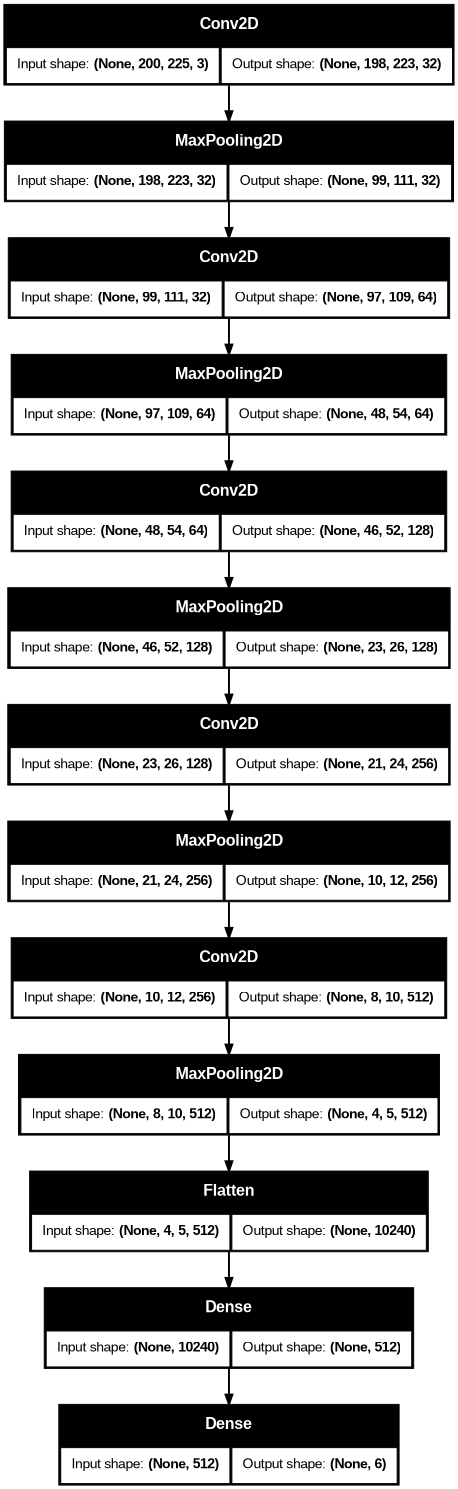

In [16]:
# Plot layers

tf.keras.utils.plot_model(model, show_shapes=True, dpi=70)

## 6.2 - Model Training

Training model dilakukan sebanyak 35 epoch. Algoritma optimasi yang digunakan untuk metode pembaruan bobot tiap epochnya menggunakan adam optimizer.

In [17]:
# Train the model

%%time
history = model.fit(train_set, epochs=35, validation_data=val_set, batch_size=batch_size)

Epoch 1/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 45s 235ms/step - accuracy: 0.5283 - loss: 1.0142 - val_accuracy: 0.4924 - val_loss: 0.8005
Epoch 2/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.5198 - loss: 0.7146 - val_accuracy: 0.4924 - val_loss: 0.7134
Epoch 3/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 19s 161ms/step - accuracy: 0.4961 - loss: 0.7099 - val_accuracy: 0.4924 - val_loss: 0.6978
Epoch 4/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 20s 175ms/step - accuracy: 0.4247 - loss: 0.7113 - val_accuracy: 0.4924 - val_loss: 0.6954
Epoch 5/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 19s 162ms/step - accuracy: 0.5190 - loss: 0.7056 - val_accuracy: 0.4924 - val_loss: 0.6973
Epoch 6/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.4475 - loss: 0.7039 - val_accuracy: 0.5076 - val_loss: 0.6954
Epoch 7/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 19s 164ms/step - accuracy: 0.5081 - loss: 0.7009 - val_accuracy: 0.4924 - val_loss: 0.6956
Epoch 8/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.4424 - loss: 0

## 6.3 - Model Evaluation

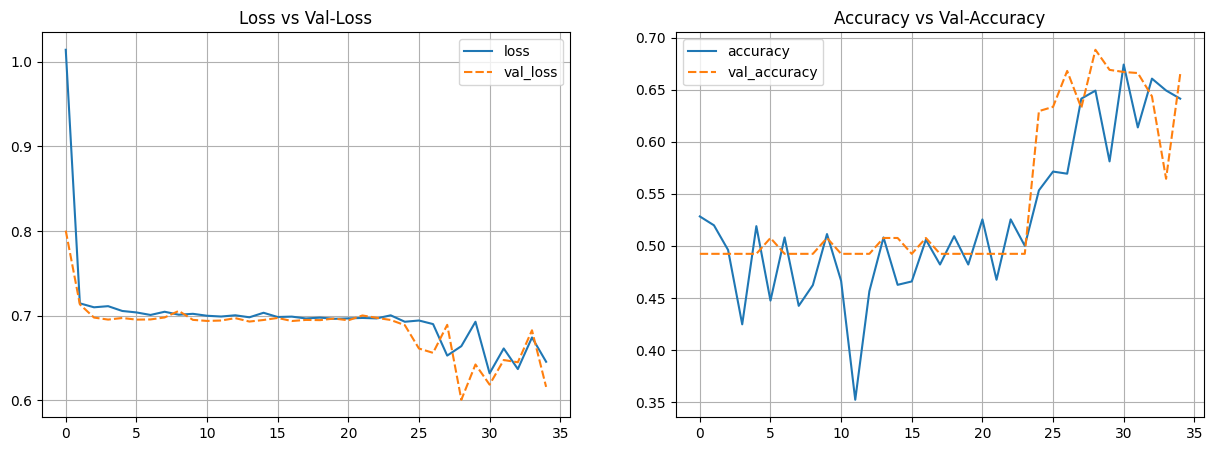

In [18]:
# Plot training results

history_df = pd.DataFrame(history.history)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=history_df[['loss', 'val_loss']])
plt.grid()
plt.title('Loss vs Val-Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=history_df[['accuracy', 'val_accuracy']])
plt.grid()
plt.title('Accuracy vs Val-Accuracy')
plt.show()

In [19]:
# Check the performance of test-set

## Get the probability
y_pred_prob = model.predict(test_set)

## Get class with maximum probability
y_pred_class = np.argmax(y_pred_prob, axis=-1)

## Display Classification Report
print(classification_report(test_set.classes, y_pred_class, target_names=np.array(list(train_set.class_indices.keys()))))

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step
                 precision    recall  f1-score   support

bleached_corals       0.83      0.51      0.63       485
 healthy_corals       0.62      0.89      0.73       438

       accuracy                           0.69       923
      macro avg       0.73      0.70      0.68       923
   weighted avg       0.73      0.69      0.68       923



Model pertama berhasil dilatih dengan waktu total 12 menit 54 detik. Berdasarkan hasil model, terlihat bahwa model memiliki performa yang buruk dimana model underfit (baik train dan validasi memiliki akurasi yang rendah). Akurasi model train pada epoch ke-35 adalah 0.64 dengan loss 0.65. Sementara itu akurasi model pada validasi ialah 0.67 dan loss 0.62. Selain itu, ketika diuji dengan data test, model hanya menghasilkan akurasi 69%. 

Dari grafik terlihat bahwa ketika epochs melewati 24, performa model mulai membaik. Ini berarti model dapat dilatih dengan jumlah epoch yang lebih banyak jika ingin menghasilkan model yang lebih baik. Namun hal tersebut akan memakan waktu yang lebih lama sehingga pada project ini epoch dibatasi hanya 35 saja.

# 7 Model Transfer Learning

Untuk memperbaiki performa dari klasifikasi data, akan dilakukan pembuatan model melalui transfer learning. Adapun model yang digunakan untuk transfer learning adalah model ResNet50. ResNet digunakan sebagai model transfer learning karena dapat mengatasi penurunan gradien yang signifikan (Rastogi A., 2022). Selain itu, penggunaan transfer learning dilakukan sebagai alternatif karena kita tidak perlu melatih model dengan waktu yang sangat lama untuk mendapatkan performa yang jauh lebih baik

## 7.1 Preprocessing

In [20]:
# Define hyperparameters

img_height= 200
img_width= 225
batch_size= 64

In [21]:
# Download pretrained model

pretrained_model_resnet50 = ResNet50(weights='imagenet', include_top=False, input_shape=(img_height,img_width, 3))
pretrained_model_resnet50.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [22]:
# Create batch generator for train-set, val-set, and test-set

train_datagen_tl_resnet50 = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_resnet50)

train_set_tl_resnet50 = train_datagen_tl_resnet50.flow_from_directory(train_path,
                                                    target_size=(img_height,img_width),
                                                    class_mode='sparse',
                                                    batch_size=batch_size,
                                                    shuffle=True,
                                                    seed=2)

val_datagen_tl_resnet50 = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_resnet50)

val_set_tl_resnet50 = val_datagen_tl_resnet50.flow_from_directory(val_path,
                                                  target_size=(img_height,img_width),
                                                  class_mode='sparse',
                                                  batch_size=batch_size,
                                                  shuffle=True,
                                                  seed=2)

test_datagen_tl_resnet50 = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_resnet50)

test_set_tl_resnet50 = test_datagen_tl_resnet50.flow_from_directory(test_path,
                                                  target_size=(img_height,img_width),
                                                  class_mode='sparse',
                                                  batch_size=batch_size,
                                                  shuffle=False,
                                                  seed=2)

Found 7384 images belonging to 2 classes.
Found 985 images belonging to 2 classes.
Found 923 images belonging to 2 classes.


# 7.2 Model Definition

Model didefinisikan secara sequential menggunakan transfer learning dengan ResNet50. Selanjutnya dilakukan fine-tuning terhadap model dengan menambahkan convolutional layer 2D dengan 128 filters dengan kernel size 3 x 3 dan activation function relu. Sementara itu, ukuran max pool layer lebih kecil dari kernel size yaitu sebesar 2 x 2 untuk mencegah kehilangan informasi meskipun dilakukan downsampling pada data. Selanjutnya, dilakukan flattening untuk mengkonversi layer multidimensional menjadi satu dimensi vektor. Lalu terdapat pembentukan 215 dense pada hidden layers dengan activation function relu. Terakhir, output layer terdiri dari 6 dense dengan fungsi aktivasi softmax.

In [23]:
# Clear session

seed = 20
tf.keras.backend.clear_session()
np.random.seed(seed)
tf.random.set_seed(seed)

In [24]:
# Create Sequential API model

model_tl_resnet50 = Sequential()
model_tl_resnet50.add(pretrained_model_resnet50)
model_tl_resnet50.add(Conv2D(128, (3,3), activation='relu'))
model_tl_resnet50.add(MaxPooling2D(2, 2))
model_tl_resnet50.add(Flatten())
model_tl_resnet50.add(Dense(128, activation='relu'))
model_tl_resnet50.add(Dense(6, activation='softmax'))

# Compile
model_tl_resnet50.compile(loss='sparse_categorical_crossentropy',
                       optimizer='adam',
                       metrics=['accuracy'])
model_tl_resnet50.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 6, 128)      │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        98,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,046,342 (99.36 MB)

 Trainable params: 2,458,630 (9.38 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

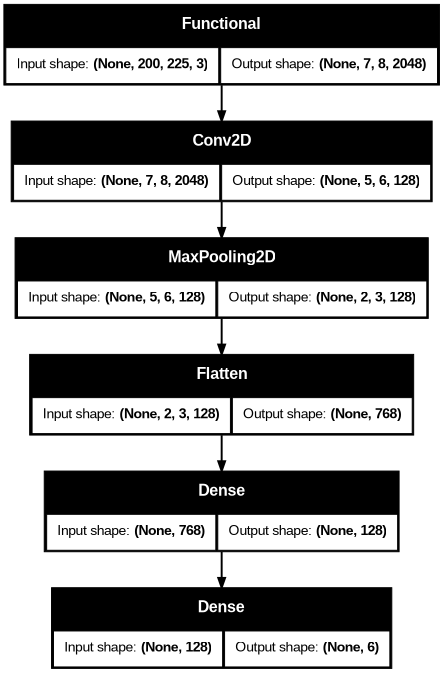

In [25]:
# Plot layers

tf.keras.utils.plot_model(model_tl_resnet50, show_shapes=True, dpi=70)

# 7.3 Model Training

Training model dilakukan sebanyak 35 epoch. Algoritma optimasi yang digunakan untuk metode pembaruan bobot tiap epochnya menggunakan adam optimizer.

In [26]:
# Train the model

%%time
history_tl_resnet50 = model_tl_resnet50.fit(train_set_tl_resnet50, epochs=35, validation_data=val_set_tl_resnet50, batch_size=batch_size)

Epoch 1/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 65s 445ms/step - accuracy: 0.7402 - loss: 1.0255 - val_accuracy: 0.8284 - val_loss: 0.3806
Epoch 2/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 314ms/step - accuracy: 0.9313 - loss: 0.1812 - val_accuracy: 0.8406 - val_loss: 0.3606
Epoch 3/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 317ms/step - accuracy: 0.9871 - loss: 0.0562 - val_accuracy: 0.8548 - val_loss: 0.3495
Epoch 4/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 314ms/step - accuracy: 0.9972 - loss: 0.0268 - val_accuracy: 0.8843 - val_loss: 0.3284
Epoch 5/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 316ms/step - accuracy: 0.9981 - loss: 0.0210 - val_accuracy: 0.8711 - val_loss: 0.3411
Epoch 6/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 317ms/step - accuracy: 0.9982 - loss: 0.0187 - val_accuracy: 0.8822 - val_loss: 0.3365
Epoch 7/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 316ms/step - accuracy: 0.9984 - loss: 0.0161 - val_accuracy: 0.8761 - val_loss: 0.3488
Epoch 8/35
116/116 ━━━━━━━━━━━━━━━━━━━━ 37s 317ms/step - accuracy: 0.9978 - loss: 0

## 7.4 Model Evaluation

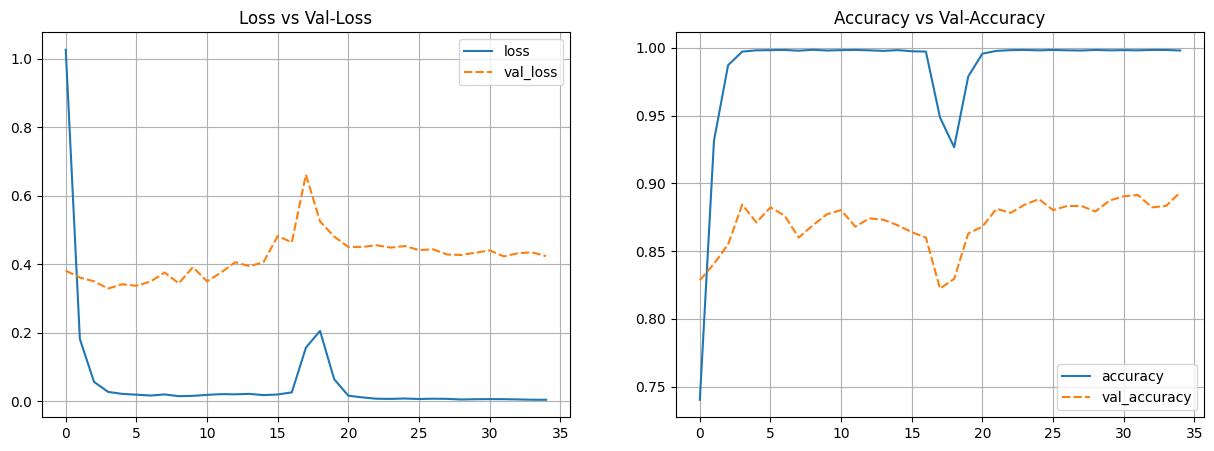

In [27]:
# Plot training results

history_tl_resnet50_df = pd.DataFrame(history_tl_resnet50.history)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=history_tl_resnet50_df[['loss', 'val_loss']])
plt.grid()
plt.title('Loss vs Val-Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=history_tl_resnet50_df[['accuracy', 'val_accuracy']])
plt.grid()
plt.title('Accuracy vs Val-Accuracy')
plt.show()

In [28]:
# Check the performance of test-set

## Get the probability
y_pred_prob_tl_resnet50 = model_tl_resnet50.predict(test_set_tl_resnet50)

## Get class with maximum probability
y_pred_class_tl_resnet50 = np.argmax(y_pred_prob_tl_resnet50, axis=-1)

## Display Classification Report
print(classification_report(test_set_tl_resnet50.classes, y_pred_class_tl_resnet50, target_names=np.array(list(train_set_tl_resnet50.class_indices.keys()))))

15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 633ms/step
                 precision    recall  f1-score   support

bleached_corals       0.95      0.88      0.91       485
 healthy_corals       0.87      0.95      0.91       438

       accuracy                           0.91       923
      macro avg       0.91      0.91      0.91       923
   weighted avg       0.91      0.91      0.91       923



Terlihat bahwa model dengan transfer learning menghasilkan performa yang jauh lebih baik dibandingkan model pertama dengan total waktu training model 18 menit 57 detik. Model ini menghasilkan akurasi train 0.998 dengan loss 0.0038 dan akurasi validasi 0.89 dengan loss sekitar 0.42. Hal ini jauh lebih baik daripada model pertama yang menghasilkan performa underfit. Meskipun begitu, model tampak overfit karena akurasi train dan validasi memiliki gap yang lumayan jauh (sekitar 0.1 atau 10%). Namun, ketika diuji dengan data tes, akurasi terbilang memuaskan (91%) sehingga model ini layak disimpan untuk inferensi data.

# 8 Model Saving

Model yang di save adalah model transfer learning menggunakan ResNet50 karena memiliki performa yang jauh lebih baik dibandingkan dengan model pertama.

In [29]:
# save model

model_tl_resnet50.save('model.keras', include_optimizer = True)

# 9. Model Inference

Inferensi model dilakukan pada notebook `P2G7_bara_inf.ipynb`

# 10. Kesimpulan

Pada project ini telah berhasil dilakukan pembuatan model CNN melalui transfer learning (ResNet50) dan fine-tuning model untuk klasifikasi karang sehat (healthy_corals) dan karang bleach (bleached_corals) dengan akurasi train model 0.99 dan validation model 0.89. Dengan akurasi tersebut, model sudah mampu membedakan sebagian besar mana karang yang sehat dan mana karang yang bleach. Ketika diuji dengan data test Tingkat presisi untuk klasifikasi karang bleach pada model adalah 95 persen. Sementara itu, tingkat presisi untuk karang healthy adalah 87 persen. Oleh karena itu, model ini telah berhasil menyelesaikan objective, yaitu untuk membantu restorasi ekosistem terumbu karang pada karang yang mengalami bleaching sehingga identifikasi karang bleach yang presisi lebih penting dalam kasus ini.

Saran untuk perbaikan model selanjutnya agar data training yang digunakan lebih banyak dan bervariasi sehingga tidak perlu dilakukan terlalu banyak augmentasi image yang membuat data gambar sedikit terdistorsi. Selain itu, bisa dicoba model transfer learning lain yang mampu membuat model lebih goodfit. Pada model ini terdapat gap akurasi yang lumayan jauh antara train dan validation model (99% dan 89%) sehingga alangkah lebih baik jika model benar-benar goodfit (misal akurasi train model 95% dan akurasi validasi 94%).